In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cuda


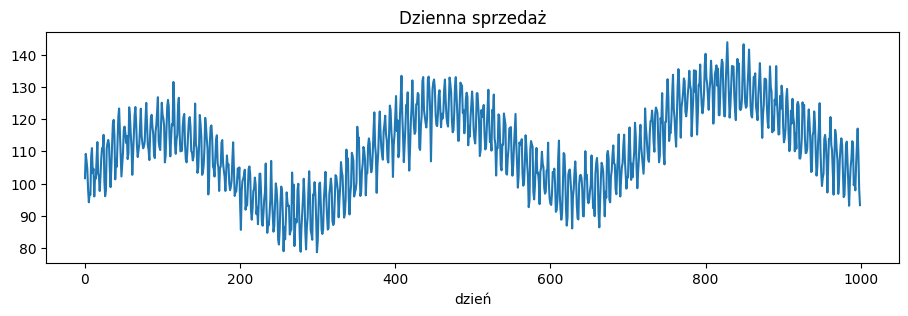

In [10]:
# generowanie danych sprzedażowych
def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02*t
    tygodniowa = 8*np.sin(2*np.pi*t/7)
    roczna = 15*np.sin(2*np.pi*t/365)
    szum = np.random.randn(n)*3

    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)


seria = generuj_sprzedaz(1000)

plt.figure(figsize=(11, 3))
plt.plot(seria)
plt.title('Dzienna sprzedaż')
plt.xlabel('dzień')
plt.show()

In [4]:
# podział chronologiczny i standaryzacja
n = len(seria)

i_tr = int(0.7*n)
i_va = int(0.85*n)

mu = seria[:i_tr].mean()
sd = seria[:i_tr].std()

s = (seria - mu) / sd

print(f'Trening: 0..{i_tr}')
print(f'Walidacja: {i_tr}..{i_va}')
print(f'Test: {i_va}..{n}')

Trening: 0..700
Walidacja: 700..850
Test: 850..1000


In [5]:
# przygotowanie okien wejściowych
OKNO = 28

def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i])
        Y.append(s[i])
    return (
        np.array(X, np.float32)[..., None],
        np.array(Y, np.float32)[:, None]
    )


def przygotuj_dane(okno):
    Xtr, Ytr = zrob_okna(s, okno, okno, i_tr)
    Xva, Yva = zrob_okna(s, okno, i_tr, i_va)
    Xte, Yte = zrob_okna(s, okno, i_va, n)

    to_t = lambda a: torch.tensor(a).to(DEVICE)

    return tuple(map(to_t, (Xtr, Ytr, Xva, Yva, Xte, Yte)))


Xtr, Ytr, Xva, Yva, Xte, Yte = przygotuj_dane(OKNO)

print('Kształty:', Xtr.shape, Xva.shape, Xte.shape)

Kształty: torch.Size([672, 28, 1]) torch.Size([150, 28, 1]) torch.Size([150, 28, 1])


In [6]:
# model GRU i uczenie
class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def trenuj(model, Xtr, Ytr, Xva, Yva,
           epoki=40, lr=1e-2, batch=64):

    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()

    best = 1e9
    best_state = None
    najlepsza_epoka = 0

    hist_tr = []
    hist_va = []

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(len(Xtr))

        for i in range(0, len(Xtr), batch):
            idx = perm[i:i+batch]

            opt.zero_grad()
            L(model(Xtr[idx]), Ytr[idx]).backward()
            opt.step()

        model.eval()

        with torch.no_grad():
            tr = L(model(Xtr), Ytr).item()
            va = L(model(Xva), Yva).item()

        hist_tr.append(tr)
        hist_va.append(va)

        if va < best:
            best = va
            najlepsza_epoka = ep + 1
            best_state = {
                k: val.clone()
                for k, val in model.state_dict().items()
            }

    model.load_state_dict(best_state)

    return model, hist_tr, hist_va, najlepsza_epoka

Najlepsza epoka: 37
Najlepsza strata walidacyjna: 0.082233


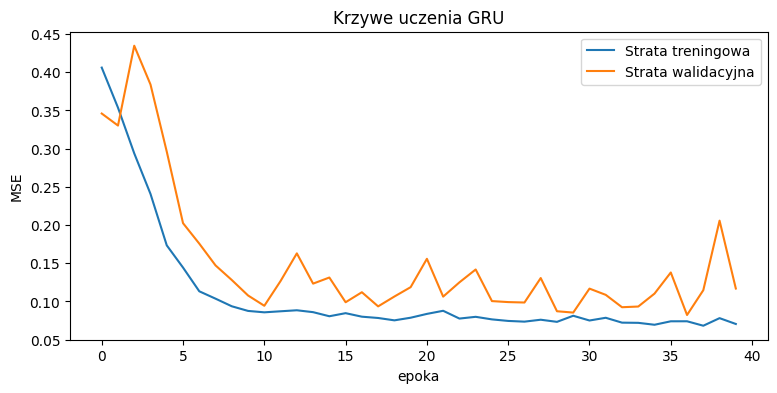

In [7]:
# trening modelu bazowego
torch.manual_seed(0)

model = ModelGRU(32)

model, hist_tr, hist_va, najlepsza_epoka = trenuj(
    model, Xtr, Ytr, Xva, Yva,
    epoki=40, lr=1e-2, batch=64
)

print('Najlepsza epoka:', najlepsza_epoka)
print(f'Najlepsza strata walidacyjna: {min(hist_va):.6f}')

plt.figure(figsize=(9, 4))

plt.plot(hist_tr, label='Strata treningowa')
plt.plot(hist_va, label='Strata walidacyjna')

plt.title('Krzywe uczenia GRU')
plt.xlabel('epoka')
plt.ylabel('MSE')
plt.legend()
plt.show()

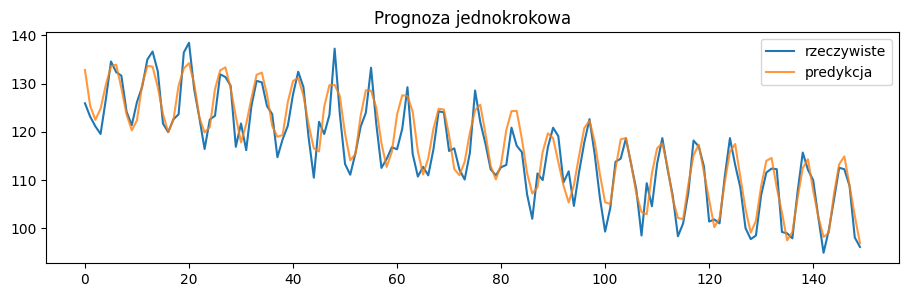

In [9]:
# prognoza jednokrokowa i baseline
model.eval()

with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()

pred_raw = pred*sd + mu
true_raw = Yte.cpu().numpy().ravel()*sd + mu

plt.figure(figsize=(11, 3))

plt.plot(true_raw, label='rzeczywiste')
plt.plot(pred_raw, label='predykcja', alpha=0.8)

plt.title('Prognoza jednokrokowa')
plt.legend()
plt.show()


In [11]:
def mae(a, b):
    return float(np.mean(np.abs(a-b)))

def rmse(a, b):
    return float(np.sqrt(np.mean((a-b)**2)))


tgt = np.arange(i_va, n)

naive = seria[tgt-1]
seasonal = seria[tgt-7]

ma = np.array([
    seria[i-OKNO:i].mean()
    for i in tgt
], np.float32)


print(f'{"metoda":16s} {"MAE":>8s} {"RMSE":>8s}')

print(f'{"GRU":16s} {mae(true_raw,pred_raw):8.2f} {rmse(true_raw,pred_raw):8.2f}')
print(f'{"naiwny (t-1)":16s} {mae(true_raw,naive):8.2f} {rmse(true_raw,naive):8.2f}')
print(f'{"sezonowy (t-7)":16s} {mae(true_raw,seasonal):8.2f} {rmse(true_raw,seasonal):8.2f}')
print(f'{"śr. ruchoma":16s} {mae(true_raw,ma):8.2f} {rmse(true_raw,ma):8.2f}')

metoda                MAE     RMSE
GRU                  2.91     3.54
naiwny (t-1)         6.11     7.19
sezonowy (t-7)       3.25     4.09
śr. ruchoma          5.82     6.81


In [12]:
# prognoza wielokrokowa 14 dni
H = 14

def rollout(model, t0, okno):
    historia = s[t0-okno:t0].tolist()
    preds = []

    model.eval()

    for h in range(H):
        x = torch.tensor(
            np.array(historia[-okno:], np.float32)
        ).reshape(1, okno, 1).to(DEVICE)

        with torch.no_grad():
            nx = model(x).item()

        preds.append(nx)
        historia.append(nx)

    return np.array(preds)*sd + mu

In [13]:
def ocena_wielokrokowa(model, okno):
    starty = range(i_va, n-H+1, H)

    prawda = []
    gru = []
    sezonowy = []
    naiwny = []

    for t0 in starty:
        prawda.append(seria[t0:t0+H])

        gru.append(
            rollout(model, t0, okno)
        )

        sezonowy.append(
            [seria[t0-7+(h % 7)] for h in range(H)]
        )

        naiwny.append(
            [seria[t0-1] for h in range(H)]
        )

    return (
        np.array(prawda),
        np.array(gru),
        np.array(sezonowy),
        np.array(naiwny)
    )


prawda14, gru14, sezonowy14, naiwny14 = ocena_wielokrokowa(
    model, OKNO
)

print('Liczba startów:', len(prawda14))

print(f'{"metoda":16s} {"MAE":>8s} {"RMSE":>8s}')

print(f'{"GRU":16s} {mae(prawda14,gru14):8.2f} {rmse(prawda14,gru14):8.2f}')
print(f'{"sezonowy":16s} {mae(prawda14,sezonowy14):8.2f} {rmse(prawda14,sezonowy14):8.2f}')
print(f'{"naiwny":16s} {mae(prawda14,naiwny14):8.2f} {rmse(prawda14,naiwny14):8.2f}')

Liczba startów: 10
metoda                MAE     RMSE
GRU                  4.05     5.02
sezonowy             3.51     4.28
naiwny              11.44    13.29


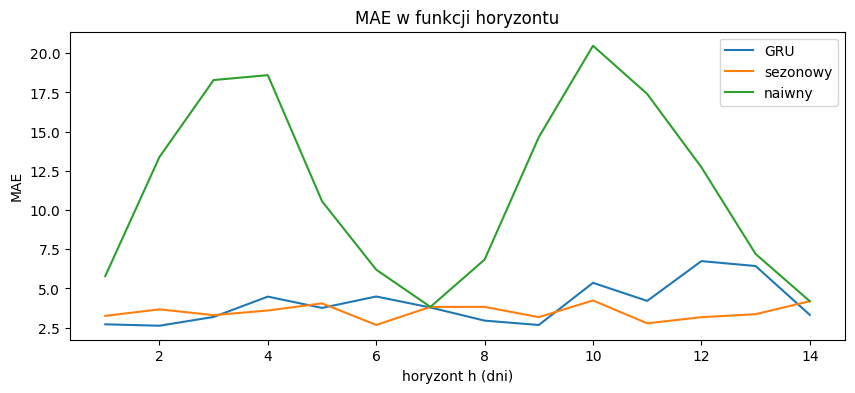

In [14]:
# wykres MAE dla kolejnych dni prognozy
plt.figure(figsize=(10, 4))

plt.plot(
    range(1, H+1),
    np.mean(np.abs(prawda14-gru14), axis=0),
    label='GRU'
)

plt.plot(
    range(1, H+1),
    np.mean(np.abs(prawda14-sezonowy14), axis=0),
    label='sezonowy'
)

plt.plot(
    range(1, H+1),
    np.mean(np.abs(prawda14-naiwny14), axis=0),
    label='naiwny'
)

plt.title('MAE w funkcji horyzontu')
plt.xlabel('horyzont h (dni)')
plt.ylabel('MAE')
plt.legend()
plt.show()

In [15]:
# wpływ długości okna
wyniki_okien = []
modele = {}

for okno in [3, 7, 28]:
    for seed in [0, 1]:

        torch.manual_seed(seed)
        np.random.seed(seed)

        Xtr_, Ytr_, Xva_, Yva_, Xte_, Yte_ = przygotuj_dane(okno)

        m = ModelGRU(32)

        m, h_tr, h_va, ep = trenuj(
            m, Xtr_, Ytr_, Xva_, Yva_,
            epoki=40, lr=1e-2, batch=64
        )

        m.eval()

        with torch.no_grad():
            pred = m(Xte_).cpu().numpy().ravel()

        pred_raw = pred*sd + mu
        true_raw = Yte_.cpu().numpy().ravel()*sd + mu

        p14, g14, sez14, nai14 = ocena_wielokrokowa(
            m, okno
        )

        wynik = {
            'okno': okno,
            'seed': seed,
            'val': min(h_va),
            'epoka': ep,
            'mae1': mae(true_raw, pred_raw),
            'mae14': mae(p14, g14)
        }

        wyniki_okien.append(wynik)
        modele[(okno, seed)] = m

        print(f'OKNO = {okno}, seed = {seed}')
        print(f"Walidacja MSE: {wynik['val']:.6f}")
        print(f"Najlepsza epoka: {wynik['epoka']}")
        print(f"MAE 1-krok: {wynik['mae1']:.4f}")
        print(f"MAE 14-krok: {wynik['mae14']:.4f}")
        print()

OKNO = 3, seed = 0
Walidacja MSE: 0.256735
Najlepsza epoka: 5
MAE 1-krok: 4.9997
MAE 14-krok: 7.4964

OKNO = 3, seed = 1
Walidacja MSE: 0.248571
Najlepsza epoka: 5
MAE 1-krok: 5.0364
MAE 14-krok: 7.8235

OKNO = 7, seed = 0
Walidacja MSE: 0.085545
Najlepsza epoka: 32
MAE 1-krok: 2.9039
MAE 14-krok: 4.3743

OKNO = 7, seed = 1
Walidacja MSE: 0.089618
Najlepsza epoka: 39
MAE 1-krok: 2.8806
MAE 14-krok: 4.0354

OKNO = 28, seed = 0
Walidacja MSE: 0.082233
Najlepsza epoka: 37
MAE 1-krok: 2.9131
MAE 14-krok: 4.0525

OKNO = 28, seed = 1
Walidacja MSE: 0.085022
Najlepsza epoka: 27
MAE 1-krok: 3.0090
MAE 14-krok: 4.4867



In [16]:
# tabela wyników
print("WYNIKI DLA POSZCZEGÓLNYCH ZIAREN")
print(f"{'OKNO':>6} {'Seed':>6} {'Val MSE':>12} {'MAE 1':>10} {'MAE 14':>10}")

for w in wyniki_okien:
    print(
        f"{w['okno']:6d} "
        f"{w['seed']:6d} "
        f"{w['val']:12.6f} "
        f"{w['mae1']:10.4f} "
        f"{w['mae14']:10.4f}"
    )


print("\nŚREDNIE I ODCHYLENIA STANDARDOWE")

for okno in [3, 7, 28]:
    w = [x for x in wyniki_okien if x['okno'] == okno]

    for nazwa in ['val', 'mae1', 'mae14']:
        wartosci = [x[nazwa] for x in w]

        print(
            f"OKNO={okno}, {nazwa}: "
            f"{np.mean(wartosci):.4f} ± {np.std(wartosci):.4f}"
        )

    print()


najlepsze_okno = min(
    [3, 7, 28],
    key=lambda okno: np.mean([
        x['val'] for x in wyniki_okien
        if x['okno'] == okno
    ])
)

print("NAJLEPSZE OKNO WEDŁUG WALIDACJI:", najlepsze_okno)

WYNIKI DLA POSZCZEGÓLNYCH ZIAREN
  OKNO   Seed      Val MSE      MAE 1     MAE 14
     3      0     0.256735     4.9997     7.4964
     3      1     0.248571     5.0364     7.8235
     7      0     0.085545     2.9039     4.3743
     7      1     0.089618     2.8806     4.0354
    28      0     0.082233     2.9131     4.0525
    28      1     0.085022     3.0090     4.4867

ŚREDNIE I ODCHYLENIA STANDARDOWE
OKNO=3, val: 0.2527 ± 0.0041
OKNO=3, mae1: 5.0180 ± 0.0183
OKNO=3, mae14: 7.6600 ± 0.1635

OKNO=7, val: 0.0876 ± 0.0020
OKNO=7, mae1: 2.8922 ± 0.0117
OKNO=7, mae14: 4.2049 ± 0.1695

OKNO=28, val: 0.0836 ± 0.0014
OKNO=28, mae1: 2.9611 ± 0.0480
OKNO=28, mae14: 4.2696 ± 0.2171

NAJLEPSZE OKNO WEDŁUG WALIDACJI: 28


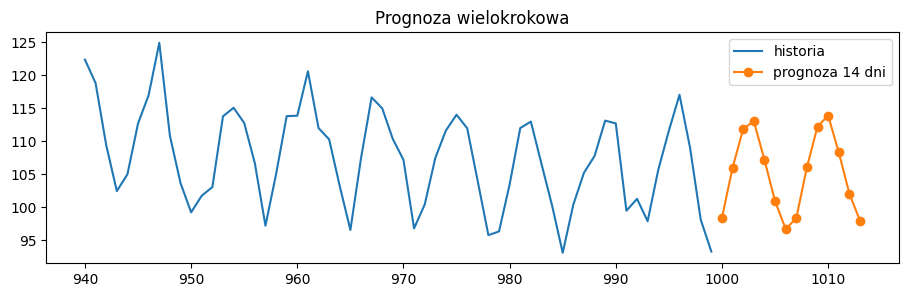

In [17]:
# prognoza na 14 dni poza końcem szeregu
najlepszy_wynik = min(
    [x for x in wyniki_okien if x['okno'] == najlepsze_okno],
    key=lambda x: x['val']
)

model_najlepszy = modele[
    (najlepsze_okno, najlepszy_wynik['seed'])
]

okno = s[n-najlepsze_okno:].tolist()
preds = []

model_najlepszy.eval()

for i in range(H):
    x = torch.tensor(
        np.array(okno[-najlepsze_okno:], np.float32)
    ).reshape(1, najlepsze_okno, 1).to(DEVICE)

    with torch.no_grad():
        nx = model_najlepszy(x).item()

    preds.append(nx)
    okno.append(nx)

preds_raw = np.array(preds)*sd + mu

plt.figure(figsize=(11, 3))

plt.plot(
    range(n-60, n),
    seria[n-60:],
    label='historia'
)

plt.plot(
    range(n, n+H),
    preds_raw,
    'o-',
    label=f'prognoza {H} dni'
)

plt.legend()
plt.title('Prognoza wielokrokowa')
plt.show()